<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet5%20PBL/Praktikum%201%20(JS5)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Persiapan Lingkungan dan Import Library

In [1]:
# Instalasi pustaka hdbscan (jalankan jika menggunakan Google Colab / belum terinstall)
!pip install hdbscan

# Import modul
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
import hdbscan

#Langkah 2: Definisi Fungsi Visualisasi

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 2 + 6 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True / Referensi" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

#Langkah 3: Persiapan Dataset Kafe & Review (Menggantikan Dataset Sintetis)

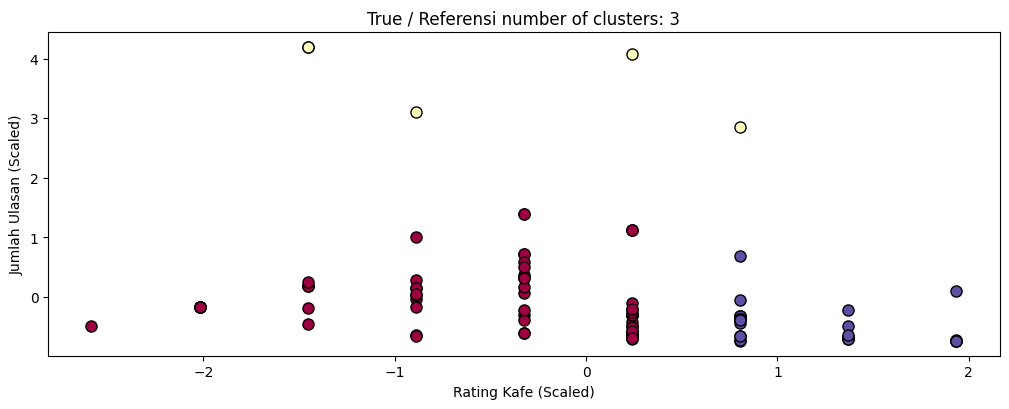

In [3]:
# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Agregasi data review per kafe
review_agg = df_reviews.groupby('cafe_id').agg({'rating': ['mean', 'count'], 'likes': 'sum'})
review_agg.columns = ['avg_review_rating', 'total_reviews_scraped', 'total_likes']
review_agg = review_agg.reset_index()

# Menggabungkan dataframe
df = pd.merge(df_cafes, review_agg, on='cafe_id', how='left').fillna(0)

# Seleksi fitur dan normalisasi skala
X_raw = df[['rating', 'review_count']].values
X = StandardScaler().fit_transform(X_raw)

# Membuat label referensi 3 kelompok untuk perbandingan awal
labels_true = KMeans(n_clusters=3, random_state=0, n_init='auto').fit_predict(X)

# Visualisasi data awal
plot(X, labels=labels_true, ground_truth=True)
plt.xlabel("Rating Kafe (Scaled)")
plt.ylabel("Jumlah Ulasan (Scaled)")
plt.show()

#Langkah 4: Uji Scale Invariance pada DBSCAN

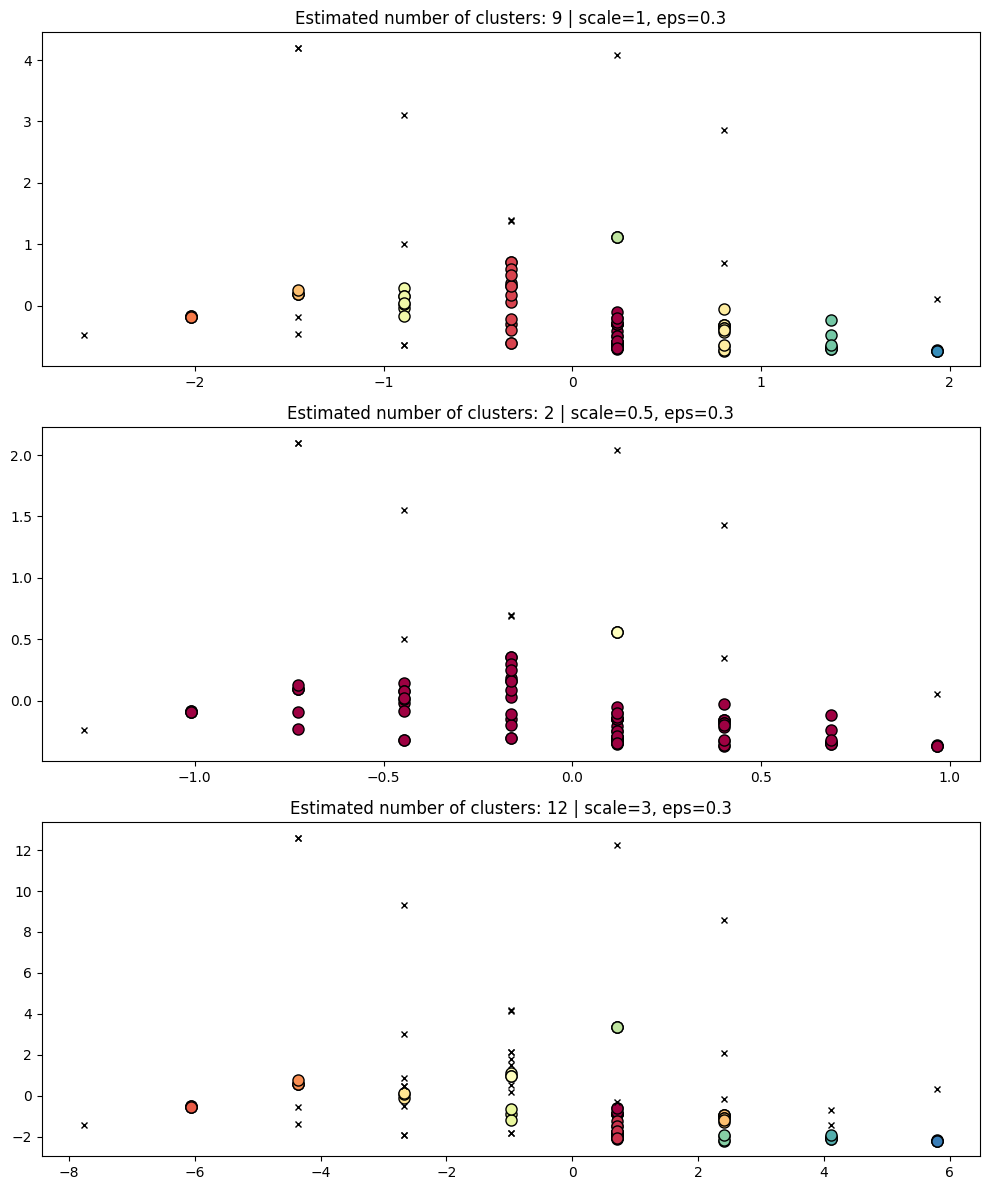

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3, min_samples=3)

for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])
plt.show()

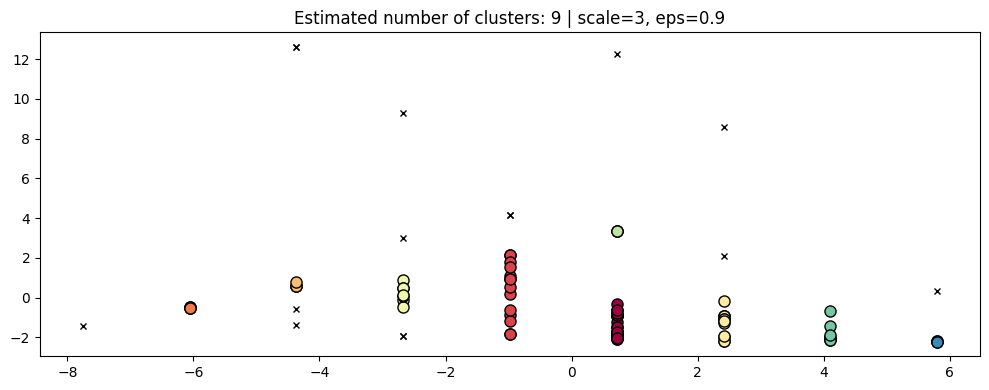

In [5]:
fig, axis = plt.subplots(1, 1, figsize=(10, 4))
dbs = DBSCAN(eps=0.9, min_samples=3).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)
plt.show()

#Langkah 5: Bandingkan dengan HDBSCAN (Lebih Robust terhadap Skala)

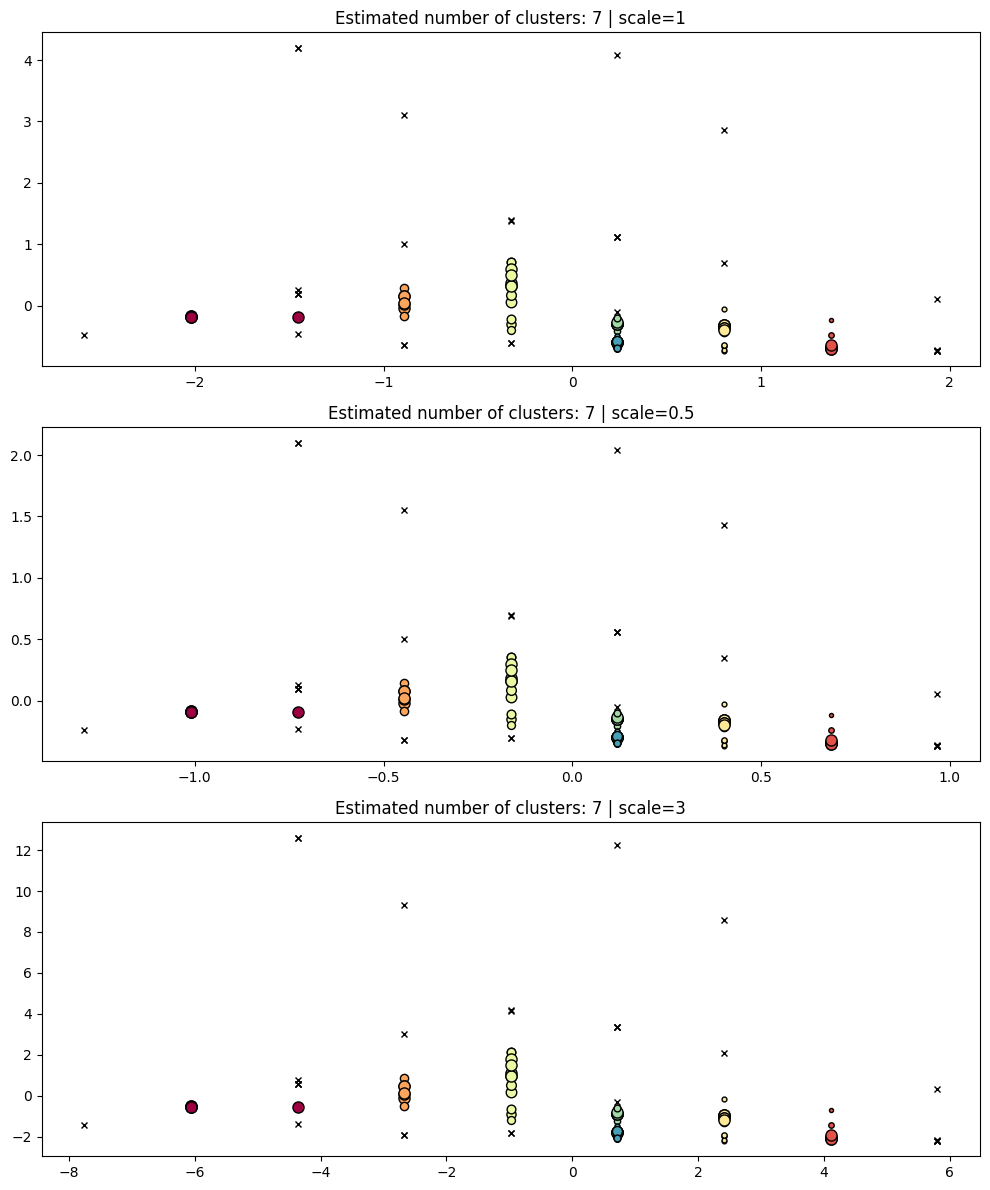

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN(min_cluster_size=5)

for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})
plt.show()

#Langkah 6: Multi-Scale Clustering (Kepadatan Data Berbeda)

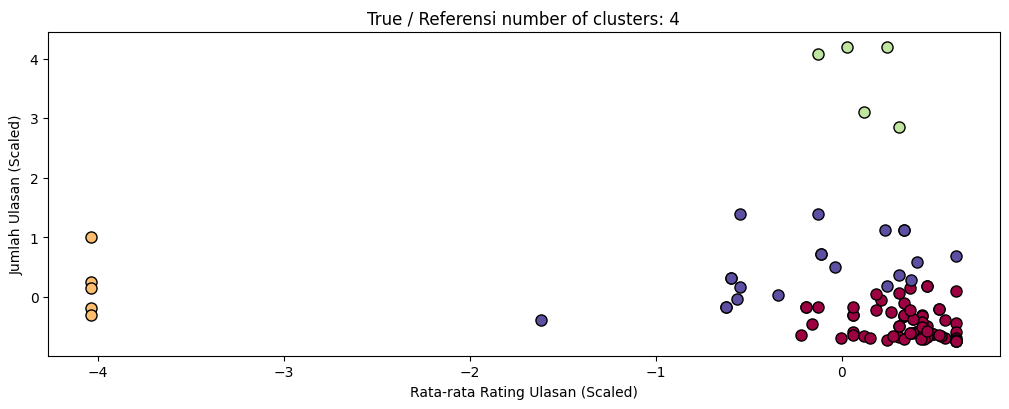

In [7]:
# Menggunakan fitur gabungan: rata-rata rating review dan jumlah review
X_multi_raw = df[['avg_review_rating', 'review_count']].values
X_multi = StandardScaler().fit_transform(X_multi_raw)

# Visualisasi sebaran dengan 4 kelompok referensi
labels_multi_ref = KMeans(n_clusters=4, random_state=0, n_init='auto').fit_predict(X_multi)
plot(X_multi, labels=labels_multi_ref, ground_truth=True)
plt.xlabel("Rata-rata Rating Ulasan (Scaled)")
plt.ylabel("Jumlah Ulasan (Scaled)")
plt.show()

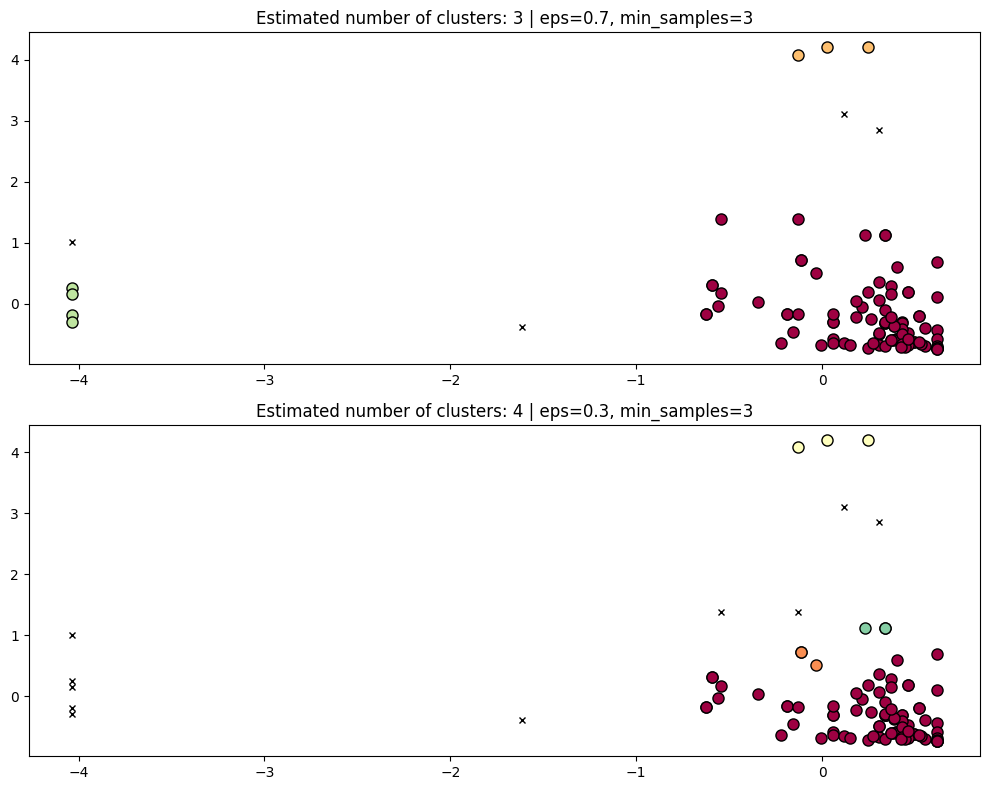

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

params = {"eps": 0.7, "min_samples": 3}
dbs = DBSCAN(**params).fit(X_multi)
plot(X_multi, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3, "min_samples": 3}
dbs = DBSCAN(**params).fit(X_multi)
plot(X_multi, dbs.labels_, parameters=params, ax=axes[1])

plt.show()

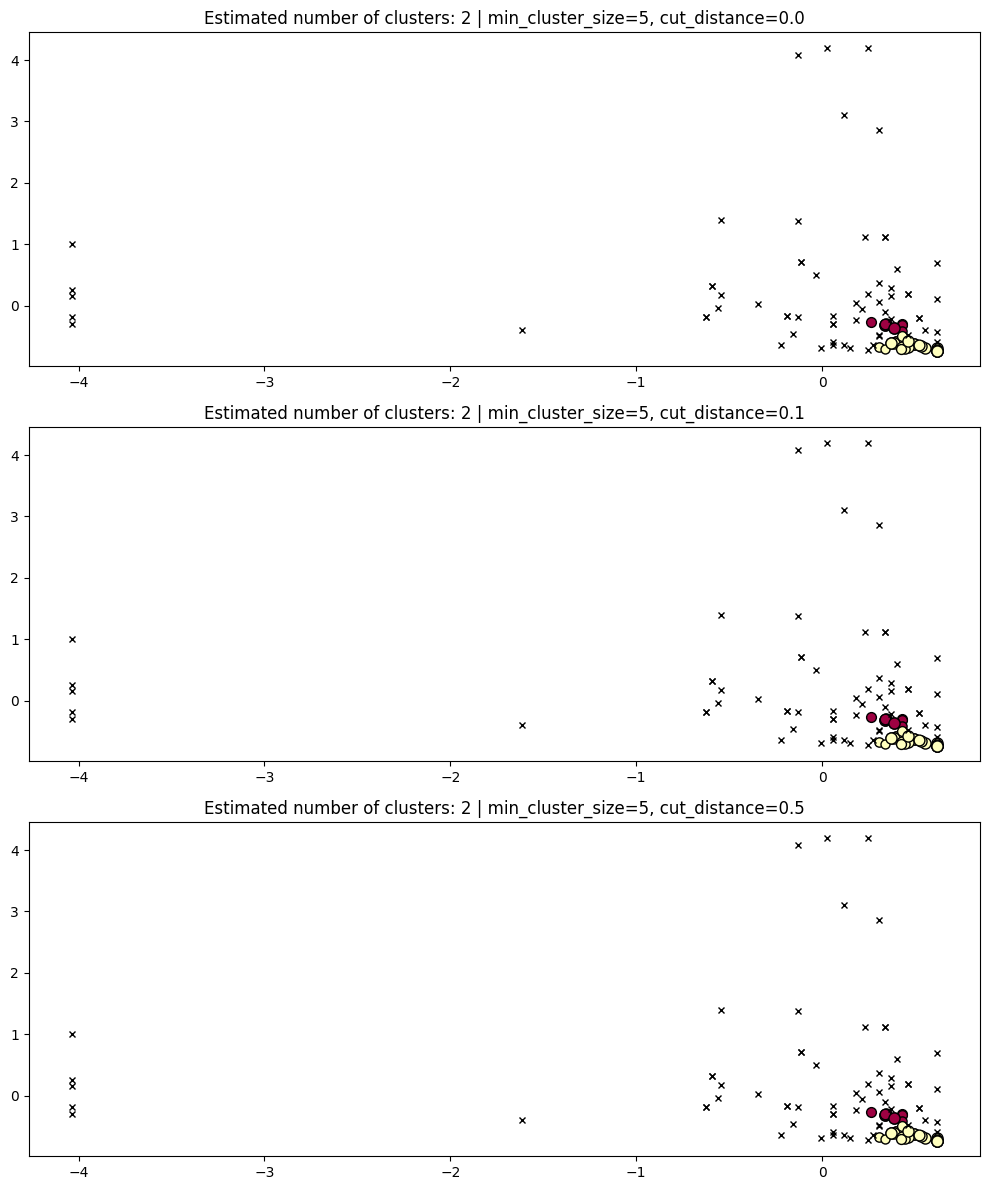

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
import hdbscan

# 1. Menyiapkan data dari cafes.csv dan reviews.csv
X_raw = df[['avg_review_rating', 'review_count']].values
X_multi = StandardScaler().fit_transform(X_raw)

# 2. Membuat 3 subplot vertikal untuk menguji variasi cut_distance / cluster_selection_epsilon
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

# Daftar nilai cut_distance (cluster_selection_epsilon) yang diuji
cut_distances = [0.0, 0.1, 0.5]

for idx, cut_dist in enumerate(cut_distances):
    # Inisialisasi HDBSCAN dengan min_cluster_size dan cluster_selection_epsilon
    hdb = hdbscan.HDBSCAN(min_cluster_size=5, cluster_selection_epsilon=cut_dist)
    hdb.fit(X_multi)

    # Memanggil fungsi plot untuk setiap subplot
    plot(
        X_multi,
        hdb.labels_,
        hdb.probabilities_,
        parameters={"min_cluster_size": 5, "cut_distance": cut_dist},
        ax=axes[idx]
    )

plt.tight_layout()
plt.show()